---
## Fitting FBK data ##
---
#### Imports

Importing and calling ...../Fitting/GenPaths.py
added to path: ['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/Fitting', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling']
PROPATH variable: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


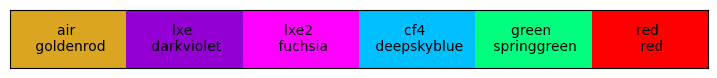

In [1]:
from GenPaths import * # this provides PROPATH which helps load stuff (and the paths to find the PDEhelpers stuff)

import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d
import time

from scipy import optimize as opt
from scipy import stats as sps
import iminuit
from iminuit import Minuit

from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
# from PDEhelpers.PNJunction import *
import PDEhelpers.PNJunction as PNJ

import PDE_fittingTools as SS

import PDEhelpers.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option


In [2]:
######## High level Fitting Functions ########
def PDE_allArgs(wlen, theta1, FF, tOxide, dp_star, Xpn, dw_star, pe, ph, smoothSigma=None, quantum = False, dh = None):
    # to use later
    if smoothSigma is not None:
        theseArgsDict = locals()
        del theseArgsDict["wlen"]
        theseArgsDict["smoothSigma"] = None

    photon = PhotonInfo(wlen, theta1, dataHelper=dh)    
    Ttotal = photon.Wave_TotalTransmission(tOxide) ### XX IMPORTANT TO USE THIS ONE
    # Ttotal = photon.Wave_TotalTransmission(tOxide)
    pn = PNJ.PNJunction(tOxide = tOxide, dp_star = dp_star, Xpn = Xpn, dw_star=dw_star, pe = pe, ph = ph)
    Wp, Wn = pn.calcW_both(photon)
    
    if quantum:
        cutinWl = 380
        nyield = np.where(wlen < cutinWl, np.sqrt(cutinWl/wlen), 1)
        pe = 1-(1-pe)**nyield
    PDE = FF * Ttotal * (Wp*pe + Wn*ph)
    
    if smoothSigma is not None: # expensive but simple/works/robust
        NperSigma = 5
        stepSize = smoothSigma / NperSigma
        NsigmaPast = 3
        newXVals = np.arange(min(wlen)-NsigmaPast*smoothSigma, max(wlen) + NsigmaPast*smoothSigma + stepSize, stepSize) # for full array at once. requires interp1d below
        fullerPDEVals = PDE_allArgs(wlen=newXVals, **theseArgsDict) # WASN'T RECURSIVELY PASSING dh BEFORE
        fullerPDEVals = gaussian_filter1d(fullerPDEVals, sigma=NperSigma) # this sigma argument is saying 'how many X points correspond to 1sigma'
        pdeInt = interp1d(newXVals, fullerPDEVals, kind='linear', fill_value=0)
        return pdeInt(wlen)     
        
    return PDE

-----------------------------
Silicon data from
   ../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
----

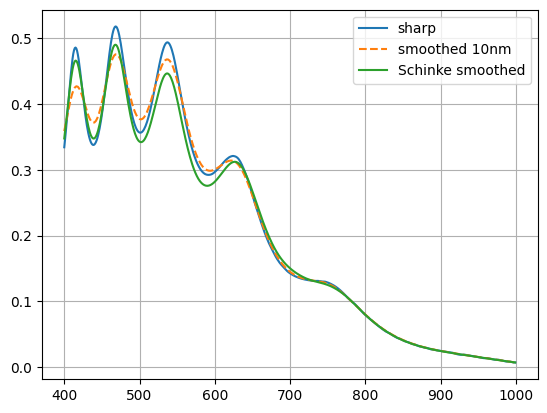

In [13]:
# plotting PDE if probabilities were 1 (for Wp, Wn)
dhSchinke = OpticsData(siDataPath="../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt")
dhAspnes = OpticsData()

print("--------------- xx ------------")
print(dhSchinke.mPathSi)
print(dhAspnes.mPathSi)

xVals = np.arange(400, 1000, 1)

yPDE_P_aspnes_sharp = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=1200, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=1, ph=0, smoothSigma=None, quantum = False, dh = dhAspnes)
yPDE_P_aspnes_smooth = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=1200, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=1, ph=0, smoothSigma=10, quantum = False, dh = dhAspnes)
yPDE_P_Schinke_sharp = PDE_allArgs(xVals, theta1=0, FF=0.6, tOxide=1200, dp_star=2.5, Xpn=2e3, dw_star=10e3, pe=1, ph=0, smoothSigma=5, quantum = False, dh = dhSchinke)

plt.plot(xVals, yPDE_P_aspnes_sharp, linestyle="-", label='sharp')
plt.plot(xVals, yPDE_P_aspnes_smooth, linestyle="--", label='smoothed 10nm')
plt.plot(xVals, yPDE_P_Schinke_sharp, linestyle="-", label='Schinke smoothed')

# plt.xlim(200, 450)
plt.legend()
plt.grid()
plt.show()

---
### Loading Data

In [10]:
print("---- Low Res Data ----")
file_path = os.path.join(PROPATH, "../veraData/FBK_IR_PDE_LowRes_stat_error_only_April18.csv")
file_path = os.path.join(PROPATH, "../veraData/FBK_IR_PDE_LowRes_stat_error_only_June2024.csv") # 1V data is higher in this dataset?
df = pd.read_csv(file_path, header=0)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())
print("Voltages:", df['Overvoltage'].unique())
print("Angles:", df['Angle'].unique())
# print(df['Wavelength'].unique())

data_angles = df['Angle'].unique()
data_voltages = df['Overvoltage'].unique()

# print("Angles:", data_angles)
# print("voltages:", data_voltages)

# df = df[(df['Wavelength'] != 399.975) & ((df['Wavelength'] < 695) | (df['Wavelength'] > 705))]

---- Low Res Data ----
     Wavelength  Angle  Overvoltage  Responsivity       PDE      PDE_error
387     790.012      0            8  2.830000e-13  0.075662  6.918510e-310
388     799.979      0            8  2.470000e-13  0.066172  6.918510e-310
389     809.978      0            8  2.220000e-13  0.059495  6.918510e-310
390     820.008      0            8  2.220000e-13  0.059251  6.918510e-310
391     830.012      0            8  2.140000e-13  0.057313  6.918510e-310
--------------------------
Overvoltage
1    49
2    49
3    49
4    49
5    49
6    49
7    49
8    49
Name: count, dtype: int64
Angle
0    392
Name: count, dtype: int64
Voltages: [1 2 3 4 5 6 7 8]
Angles: [0]


In [11]:
print("---- High Res Data ----")

file_pathHR = os.path.join(PROPATH, "../veraData/FBK_IR_PDE_HR_2_may6.csv") # this dataset has a nuisance fit that does not converge
file_pathHR = os.path.join(PROPATH, "../veraData/FBK_IR_PDE_HR_may6.csv")
dfHR = pd.read_csv(file_pathHR, header=0)
print(dfHR.tail())


data_anglesHR = dfHR['Angle'].unique()
data_voltagesHR = dfHR['Overvoltage'].unique()

print("voltages:", data_voltagesHR)
print("angles:", data_anglesHR)
print("wlen range:", dfHR['Wavelength'].min(), dfHR['Wavelength'].max())

---- High Res Data ----
     Wavelength  Angle  Overvoltage  Responsivity       PDE  PDE_error
395     488.010      0            8  1.317970e-12  0.346423   0.000507
396     490.961      0            8  1.259270e-12  0.330992   0.007925
397     493.970      0            8  1.237670e-12  0.325315   0.009137
398     496.980      0            8  1.218070e-12  0.320163   0.012406
399     499.990      0            8  1.180930e-12  0.310400   0.005496
voltages: [1 2 3 4 5 6 7 8]
angles: [0]
wlen range: 349.97 499.99


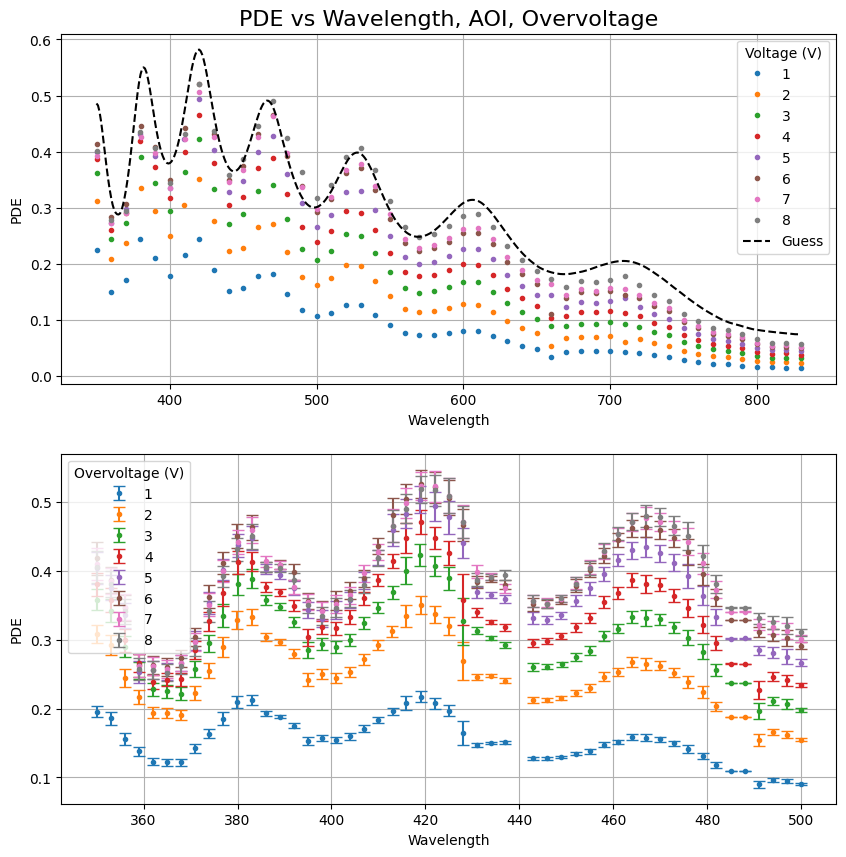

Angles: [1 2 3 4 5 6 7 8]
voltages: [1 2 3 4 5 6 7 8]


In [12]:
## Plot the data
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=False, figsize = (10, 10))

for voltage in data_voltages:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE",label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax1)

# xv4 = df[df['Overvoltage'] == 4]
for voltage in data_voltagesHR:
    dt1 = dfHR[(dfHR['Angle'] == 0) & (dfHR['Overvoltage'] == voltage)]

    dt1.plot(x='Wavelength', y = "PDE", yerr="PDE_error", capsize=4, label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)
    

# some guesses
xGuess = np.arange(df['Wavelength'].min(), df['Wavelength'].max(), 1)
test_Boring = {"FF": 0.8, "quantum": False, "smoothSigma": None, "dh":dhAspnes}
testPars = {"tOxide": 1360, "dp_star": 1, "Xpn": 0.3e3, "dw_star": 6e3, "pe": 0.95, "ph": 0.35}
yGuess = PDE_allArgs(wlen=xGuess, theta1=0, **testPars, **test_Boring)

ax1.plot(xGuess, yGuess, label = "Guess", color = "black", linestyle = "--")

ax1.legend(title = "Voltage (V)")
ax1.set_ylabel("PDE")

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

ax1.grid(), ax2.grid()
# ax2.set_xlim(380, 420)

ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
# plt.subplots_adjust(hspace=0)
plt.show()
print("Angles:", data_voltages)
print("voltages:", data_voltages)

{1: 0.486306, 2: 0.733673, 3: 0.858569, 4: 0.925484, 5: 0.961845, 6: 0.981696, 7: 0.993065, 8: 0.997103, 9: 1.0}
---- Harry Pe values ----


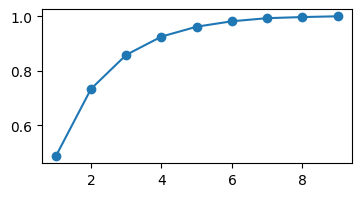

In [7]:
## Loading in Harry's PE data
file_path_pe = os.path.join(PROPATH, "../veraData/HPK_EHPAIR_183K.csv")
df_pe = pd.read_csv(file_path_pe, header=0)

# print(df_pe)
df_pe=df_pe[df_pe['Wavelength'] == 380]
# print(df_pe)

harryPe = df_pe['normalized rate'].values
harryPedict = {df_pe["Overvoltage"].values[i]: harryPe[i] for i in range(len(harryPe))}
print(harryPedict)

print("---- Harry Pe values ----")
plt.figure(figsize=(4, 2))
plt.plot(df_pe["Overvoltage"], harryPe, marker = "o")
plt.show()

---
---
## Parameters shared by everything

In [8]:
FF1 = 0.8
scaleErrors = 0.02 # do 5% errors on PDE

ttGood = 1339.3 # good thickness in nm

fixedPars_Boring = {"FF": FF1, "quantum": False, "smoothSigma": None, "dh":dhAspnes}
# really sigma is 2/2.335


---
---
## Building dataset
Relative to __S__ above, this also float $dp^*$ and floats both $P$ values for each voltage
* float global: $X_{pn}$, $dw^*$, $dp^*$
* nested float: $P_e$, $P_h$

In [9]:
##-- Buiding global dataset from HR and LR data --##
angle_0A = data_angles[0]
print(data_voltages)
voltageTracker = data_voltages

data_global_all = []
onlyData_global_all = []
for V in voltageTracker:
    # low res data
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A)]
    # tempErrors = dfA_t1['PDE'] * scaleErrors
    pdeErrors = dfA_t1['PDE_error']
    oneD_LRdict = {"wlen":dfA_t1['Wavelength'], "yVals": dfA_t1['PDE'], "yErrs": pdeErrors, "theta1": angle_0A}
    onlyData_global_all.append(oneD_LRdict)
    
    # high res data
    dft1_HR = dfHR[(dfHR['Overvoltage'] == V) & (dfHR['Angle'] == angle_0A)]
    errorsHR = dft1_HR['PDE_error']
    oneD_HRdict = {"wlen":dft1_HR['Wavelength'], "yVals": dft1_HR['PDE'], "yErrs": errorsHR, "theta1": angle_0A}
    onlyData_global_all.append(oneD_HRdict)
    
    dataDict_array = [oneD_LRdict, oneD_HRdict] # both data
    # dataDict_array = [oneD_LRdict] # only LR data
    
    # tempFixedPE = peVals_A_dict[V] if V in peVals_A_dict else 1.0
    tempFixedPE = harryPedict[V] if V in harryPedict else 1.0
    tempFixedPE = 1.0 if tempFixedPE > 1 else tempFixedPE # get rid of +1 values
    print("V:", V, "guess pe:", tempFixedPE)
    fixedNuisDict = {}
    
    floatNuisDict = {"pe": tempFixedPE, "ph": 0.15}
    floatBoundsNuisDict = {"pe": (0.0, 1.1), "ph": (0.0, 1.1)}
    odFullS = SS.OneNuisanceDataSet(oneDData=dataDict_array, nuisanceFloat=floatNuisDict, nuisanceBounds=floatBoundsNuisDict,
                                    nuisanceFixed=fixedNuisDict)
    # ndof stuff
    ndof = odFullS.CalcNDOF(xkey="wlen")
    # print("NDOF:", ndof)
    
    odFullS.extraV = V
    data_global_all.append(odFullS)

SS.CheckDataSetKey_consistent(onlyData_global_all, True);
type(data_global_all[0].oneDData);

[1 2 3 4 5 6 7 8]
V: 1 guess pe: 0.486306
V: 2 guess pe: 0.733673
V: 3 guess pe: 0.858569
V: 4 guess pe: 0.925484
V: 5 guess pe: 0.961845
V: 6 guess pe: 0.981696
V: 7 guess pe: 0.993065
V: 8 guess pe: 0.997103
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed


In [10]:
print("List of args needed:", SS.GetNames(PDE_allArgs))

fixedPars_Global = {**fixedPars_Boring}

print("\nfixed inputs:", fixedPars_Global)

floatPars_Global = {"tOxide":1340, "dp_star":0.5, "Xpn": 0.2e3, "dw_star": 5e3}
floatParBounds_Global = {"tOxide":(1000, 2500), "dp_star":(0.1, 5), "Xpn": (0.1e3, 1.5e3), "dw_star": (1.5e3, 10e3)}

x0_global_global, x0_global_global_Names = SS.BuildX0(floatDict=floatPars_Global, functionToFit=PDE_allArgs)
x0_global_global_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_Global, functionToFit=PDE_allArgs)

print("------ Case S - Vis all ------")
SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_global, globalFixed=fixedPars_Global, dataPackage=data_global_all,
                               functionToFit=PDE_allArgs, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'smoothSigma', 'quantum', 'dh']

fixed inputs: {'FF': 0.8, 'quantum': False, 'smoothSigma': None, 'dh': <PDEhelpers.OpticsDataLoader.OpticsData object at 0x16958d750>}
------ Case S - Vis all ------


394752.47340131865

In [11]:
startTime = time.time()
result_globalFit_all = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_global, bounds = x0_global_global_bounds,
                                        args=(fixedPars_Global, data_global_all, PDE_allArgs), method='migrad')
SS.GenericResiduals_Nuisance_1(globalFloat=result_globalFit_all.x, globalFixed=fixedPars_Global, dataPackage=data_global_all,
                                    functionToFit=PDE_allArgs, verbose=False)
endTime = time.time()
print("Done fit! Time taken:", int((endTime-startTime)/60), ":", int((endTime-startTime)%60))

In [ ]:
# print(result_globalFit_all)
print("score:", result_globalFit_all.fun)
resDict_fullGlobal = SS.GetResDict(result_globalFit_all, x0_global_global_Names)
resDictError_fullGlobal = SS.GetResErrorDict(result_globalFit_all, x0_global_global_Names)
print("global fit:", resDict_fullGlobal)
print("global fit errors:", resDictError_fullGlobal)
ratio_dict = {key: 100*resDictError_fullGlobal[key] / resDict_fullGlobal[key] for key in resDict_fullGlobal}
print(ratio_dict)

peFull_dict_global = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_global_all}
phFull_dict_global = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_global_all}

print("pe:", peFull_dict_global)
print("ph:", phFull_dict_global)

totalDOF = sum([dc.nDOF for dc in data_global_all]) - len(x0_global_global)
reducedChi2 = result_globalFit_all.fun / totalDOF
print("total DOF:", totalDOF)
print("Reduced chi2:", reducedChi2)

score: 2743.3052810500576
global fit: {'tOxide': 1359.5068, 'dp_star': 1.2665, 'Xpn': 320.6408, 'dw_star': 4399.2676}
global fit errors: {'tOxide': 0.1741, 'dp_star': 0.0495, 'Xpn': 3.6291, 'dw_star': 38.5499}
{'tOxide': 0.012806114688061875, 'dp_star': 3.9084090011843666, 'Xpn': 1.1318272659000352, 'dw_star': 0.8762799516901405}
pe: {1: (0.4128, 0.0015), 2: (0.599, 0.0022), 3: (0.721, 0.0026), 4: (0.7949, 0.0029), 5: (0.8423, 0.0031), 6: (0.8892, 0.0033), 7: (0.8587, 0.0032), 8: (0.8815, 0.0034)}
ph: {1: (0.0633, 0.0004), 2: (0.1088, 0.0006), 3: (0.1598, 0.0008), 4: (0.2041, 0.001), 5: (0.2499, 0.0011), 6: (0.284, 0.0012), 7: (0.312, 0.0013), 8: (0.3522, 0.0014)}
total DOF: 372
Reduced chi2: 7.3744765619625205


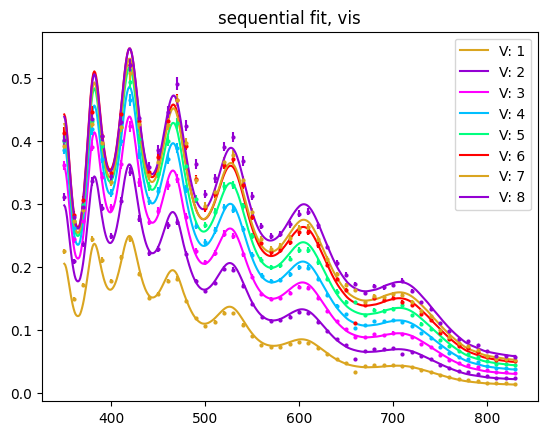

In [ ]:
for dc in data_global_all:
    pAvalanche = dc.resultDict
        
    voltage = dc.extraV
        
    col = ms.GetNextColor()
    minX, maxX = 500, 500
    for oneD in dc.oneDData:
        xwlen = oneD["wlen"]
        y = oneD["yVals"]
        yErrs = oneD["yErrs"]
        plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)
        
        minX = min(minX, min(xwlen))
        maxX = max(maxX, max(xwlen))
        # yFit_standard = PDE_allArgs(wlen=xwlen, theta1=oneD["theta1"], **otherDict, **pArgs)
        # plt.plot(xwlen, yFit_standard, color = col, linestyle="--")
    
    ### 
    xPretty = np.arange(minX, maxX, 1)
    yFit = PDE_allArgs(wlen=xPretty, **fixedPars_Global, theta1=oneD["theta1"], **resDict_fullGlobal, **pAvalanche)
    plt.plot(xPretty, yFit, color = col, label=f"V: {dc.extraV}")
        

plt.title("sequential fit, vis")
plt.legend()
plt.show()

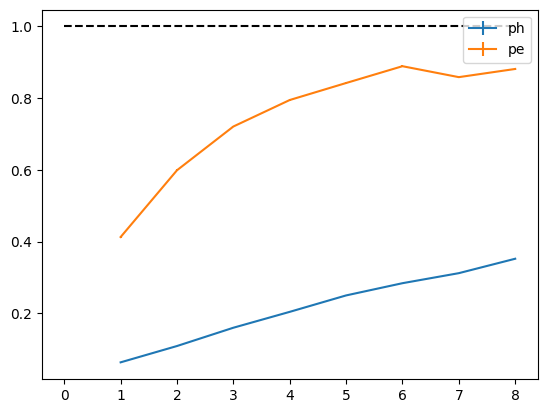

In [ ]:
yph_visS = [phFull_dict_global[voltage][0] for voltage in voltageTracker]
yphErr_visS = [phFull_dict_global[voltage][1] for voltage in voltageTracker]


ype_UV = [peFull_dict_global[voltage][0] for voltage in voltageTracker]
ypeErr_UV = [peFull_dict_global[voltage][1] for voltage in voltageTracker]

plt.errorbar(voltageTracker, yph_visS, yphErr_visS, label="ph")
plt.errorbar(voltageTracker, ype_UV, ypeErr_UV, label="pe")
plt.hlines(1.0, 0, 8, linestyle = "--", color="k")

plt.legend()